In [ ]:
# 1. Check GPU allocation
!nvidia-smi

# 2. Mount Google Drive to persist data and access the repository
from google.colab import drive
drive.mount('/content/drive')

Sun Aug 16 12:27:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# 1. Di chuyển vào thư mục chứa custom Ultralytics đã upload
# Hãy thay thế đường dẫn bên dưới bằng vị trí thực tế của bạn
%cd /content/drive/MyDrive/ppe_cv/Pruned-QAT-for-YOLOv8-on-waste-detection-tasks-for-edge-devices
# 2. Gỡ bản gốc để tránh xung đột
!pip uninstall -y ultralytics

# 3. Cài đặt bản custom (lệnh này sẽ cài đặt thư viện vào hệ thống Colab)
!pip install -e .

/content/drive/MyDrive/ppe_cv/Pruned-QAT-for-YOLOv8-on-waste-detection-tasks-for-edge-devices
Obtaining file:///content/drive/MyDrive/ppe_cv/Pruned-QAT-for-YOLOv8-on-waste-detection-tasks-for-edge-devices
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for ultralytics (pyproject.toml) ... done
  Created wheel for ultralytics: filename=ultralytics-8.3.231-0.editable-py3-none-any.whl size=11707 sha256=a52d86d020a0ccfb51d15c26cb5b48ad91e114fb7f205caa6d71dd93a4eb2782
  Stored in directory: /tmp/pip-ephem-wheel-cache-08r7j8ze/wheels/6d/54/88/b24c9a513438bdb6003f090cbfc70bfc9b5fc534848fa36efd
Successfully built ultralytics


In [ ]:
# Di chuyển về thư mục gốc của dự án
%cd /content/drive/MyDrive/ppe_cv/ppe_v2

# Kiểm tra lại xem đã đứng đúng thư mục chưa (sẽ thấy thư mục scripts, file data.yaml...)
!ls

/content/drive/MyDrive/ppe_cv/ppe_v2
assets	     demo.py			runs		 yolov8_baseline.ipynb
bench.ipynb  experiments_dagshub.ipynb	scripts		 yolov8_prune.ipynb
config.py    mlflow.db			weights
configs      README.md			yolo11n.pt
data.yaml    requirements.txt		yolov5_au.ipynb


In [ ]:
!pip install mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 117.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 122.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 101.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 30.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.0/212.0 kB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.9/123.9 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.2/132.2 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import os
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

In [ ]:
# Run sparsity training
# Note: Ensure configs/data.yaml has the correct dataset paths relative to your Drive
!python scripts/train.py \
    --mode sparsity \
    --weights /content/drive/MyDrive/ppe_cv/best_baseline_yolov8s.pt \
    --data data.yaml \
    --batch 32 \
    --epochs 80 \
    --device 0

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
New https://pypi.org/project/ultralytics/8.4.120 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.231 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/ppe_cv/ppe_v2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, finetune=None, fliplr=0.5, flipud=0.0, 

In [ ]:
import mlflow
import os
import getpass

DAGSHUB_USER = input("Nhập DagsHub Username: ")
DAGSHUB_TOKEN = getpass.getpass("Nhập DagsHub Token: ")
DAGSHUB_REPO = input("Nhập tên DagsHub Repo (VD: ppe-project): ")

os.environ["MLFLOW_TRACKING_USERNAME"] = DAGSHUB_USER
os.environ["MLFLOW_TRACKING_PASSWORD"] = DAGSHUB_TOKEN
os.environ["MLFLOW_TRACKING_URI"] = f"https://dagshub.com/{DAGSHUB_USER}/{DAGSHUB_REPO}.mlflow"


Nhập DagsHub Username: TQanh23
Nhập DagsHub Token: ··········
Nhập tên DagsHub Repo (VD: ppe-project): ppe_v2


In [ ]:
mlflow.set_experiment("YOLOv8s_Sparsity_Pruning")

with mlflow.start_run(run_name="Phase1_Sparsity"):
    print("Đang tải dữ liệu lên MLflow...")

    mlflow.log_params({
        "mode": "sparsity",
        "epochs": 80,
        "batch_size": 16,
        "sr": 0.015
    })

    weights_dir = "/content/drive/MyDrive/ppe_cv/ppe_v2/runs/train-sparsity7"

    mlflow.log_artifacts(weights_dir, artifact_path="sparsity_weights")

    print(f"Hoàn tất upload từ {weights_dir} lên MLflow!")

2026/08/16 14:46:50 INFO mlflow.tracking.fluent: Experiment with name 'YOLOv8s_Sparsity_Pruning' does not exist. Creating a new experiment.


Đang tải dữ liệu lên MLflow...
Hoàn tất upload từ /content/drive/MyDrive/ppe_cv/ppe_v2/runs/train-sparsity7 lên MLflow!
🏃 View run Phase1_Sparsity at: https://dagshub.com/TQanh23/ppe_v2.mlflow/#/experiments/15/runs/4031d3a4c0b649908fc6aaeef8be0204
🧪 View experiment at: https://dagshub.com/TQanh23/ppe_v2.mlflow/#/experiments/15


In [ ]:
# 1. Tạo thư mục configs nếu chưa tồn tại
!mkdir -p /content/drive/MyDrive/ppe_cv/ppe_v2/configs

# 2. Tạo file pipeline.yaml mặc định
!echo "paths: {}" > /content/drive/MyDrive/ppe_cv/ppe_v2/configs/pipeline.yaml

In [ ]:
# Run the visualization script
!python /content/drive/MyDrive/ppe_cv/ppe_v2/scripts/vis_bn_weight.py \
    --normal /content/drive/MyDrive/ppe_cv/best_baseline_yolov8s.pt \
    --sparse /content/drive/MyDrive/ppe_cv/ppe_v2/runs/train-sparsity7/weights/last.pt \
    --output-dir assets/

/content/drive/MyDrive/ppe_cv/ppe_v2/scripts/vis_bn_weight.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
Saved plots to /content/drive/MyDrive/ppe_cv/ppe_v2/assets


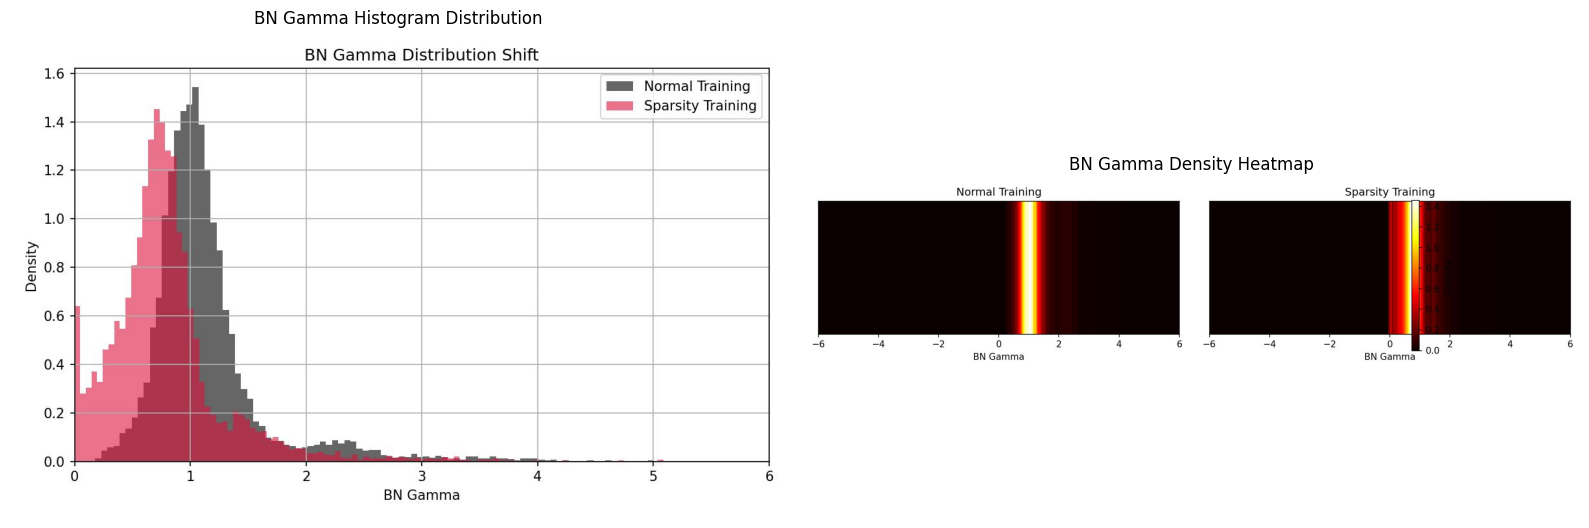

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

# Render side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

hist_path = 'assets/bn_gamma_hist.jpg'
heatmap_path = 'assets/bn_gamma_hist_heatmap.jpg'

if os.path.exists(hist_path) and os.path.exists(heatmap_path):
    axes[0].imshow(mpimg.imread(hist_path))
    axes[0].axis('off')
    axes[0].set_title("BN Gamma Histogram Distribution")

    axes[1].imshow(mpimg.imread(heatmap_path))
    axes[1].axis('off')
    axes[1].set_title("BN Gamma Density Heatmap")

    plt.tight_layout()
    plt.show()
else:
    print("Plot files not found. Check if Cell 6 executed successfully.")

In [ ]:
# Evaluate model accuracy and measure inference latency
!python scripts/val.py \
    --weight /content/drive/MyDrive/ppe_cv/ppe_v2/runs/train-sparsity7/weights/last.pt \
    --data data.yaml \
    --split test \
    --batch 16 \
    --imgsz 640

Average Latency per image: 9.36 ms
Approx FPS: 106.83
Ultralytics 8.3.231 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,067 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.6±0.3 ms, read: 66.6±26.2 MB/s, size: 71.0 KB)
val: Scanning /content/drive/MyDrive/ppe_cv/train_data/valid/labels.cache... 229 images, 19 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 229/229 1.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 2.1it/s 7.3s
                   all        229       2019      0.728      0.654      0.682      0.347
                 boots         93        201      0.633      0.562      0.559      0.219
                gloves         78        157      0.559      0.344      0.384      0.139
                helmet        130        337      0.831      0.844      0.879      0.527
              no_boots         32         65      0.656     

In [ ]:
import os

sparsity_weight_path = "/content/drive/MyDrive/ppe_cv/ppe_v2/runs/train-sparsity6/weights/last.pt"

if os.path.exists(sparsity_weight_path):
    size_mb = os.path.getsize(sparsity_weight_path) / (1024 * 1024)
    print(f"✅ Phase 1 Complete! Output checkpoint ready for Phase 2:")
    print(f"   Path: {sparsity_weight_path} ({size_mb:.2f} MB)")
else:
    print(f"❌ Checkpoint file not found at {sparsity_weight_path}. Check your run directory.")

✅ Phase 1 Complete! Output checkpoint ready for Phase 2:
   Path: /content/drive/MyDrive/ppe_cv/ppe_v2/runs/train-sparsity6/weights/last.pt (5.97 MB)
